In [39]:
# %pip install pandas os numpy sqlalchemy seaborn scikit-learn matplotlib
import pandas as pd
import os
import numpy as np
from sqlalchemy import create_engine, text


DSN = os.getenv("SEG_DB_DSN", "")
if not DSN:
    print("SEG_DB_DSN is not set. Use the existing loaded dataframes or local parquet files; do not hardcode credentials.")

engine = create_engine(DSN) if DSN else None

def que(sql):
    return pd.read_sql(sql, engine)

SEG_DB_DSN is not set. Use the existing loaded dataframes or local parquet files; do not hardcode credentials.


In [10]:
# List all data files in your active folder
import glob
print("Parquet files:", glob.glob("*.parquet"))
print("CSV files:", glob.glob("*.csv"))


Parquet files: ['seg_balances.parquet', 'seg_customers.parquet', 'seg_customers_360.parquet', 'seg_products.parquet', 'seg_revenue_monthly.parquet', 'seg_rfm_old.parquet', 'seg_tariff_current.parquet', 'seg_temp.parquet', 'seg_transactions.parquet', 'seg_transactions_archive.parquet']
CSV files: []


In [ ]:
# que("""
# select tablename
# from pg_tables
# where schemaname = 'public' and tablename like 'seg_%'
# order by 1
# """)

AttributeError: 'NoneType' object has no attribute 'cursor'

In [ ]:
# cols =[ " seg_balances",
# "seg_customers",
# "seg_customers_360",
# "seg_products",
# "seg_revenue_monthly",
# "seg_rfm_old",
# "seg_tariff_current",
# "seg_temp",
# "seg_transactions",
# "seg_transactions_archive"
# ]


In [ ]:
# def reviwer(column):
#     query_str = f" select * from {column} "
#     return que(query_str)

In [ ]:
# df_seg_balances = reviwer('seg_balances')
# df_seg_customers = reviwer('seg_customers')
# df_seg_customers_360 = reviwer('seg_customers_360')
# df_seg_products = reviwer('seg_products')
# df_seg_revenue_monthly = reviwer('seg_revenue_monthly')
# df_seg_rfm_old = reviwer('seg_rfm_old')
# df_seg_tariff_current = reviwer('seg_tariff_current')
# df_seg_transactions = reviwer('seg_transactions')
# df_seg_temp = reviwer('seg_temp')
# df_seg_transactions_archive = reviwer('seg_transactions_archive')

In [4]:
# df_seg_balances.to_parquet("seg_balances.parquet")
# df_seg_customers.to_parquet("seg_customers.parquet")
# df_seg_customers_360.to_parquet("seg_customers_360.parquet")
# df_seg_products.to_parquet("seg_products.parquet")
# df_seg_revenue_monthly.to_parquet("seg_revenue_monthly.parquet")
# df_seg_rfm_old.to_parquet("seg_rfm_old.parquet")
# df_seg_tariff_current.to_parquet("seg_tariff_current.parquet")
# df_seg_transactions.to_parquet("seg_transactions.parquet")
# df_seg_temp.to_parquet("seg_temp.parquet")
# df_seg_transactions_archive.to_parquet("seg_transactions_archive.parquet")


In [1]:
import pandas as pd

files = {
    'df_seg_balances': 'seg_balances.parquet',
    'df_seg_customers': 'seg_customers.parquet',
    'df_seg_customers_360': 'seg_customers_360.parquet',
    'df_seg_products': 'seg_products.parquet',
    'df_seg_revenue_monthly': 'seg_revenue_monthly.parquet',
    'df_seg_rfm_old': 'seg_rfm_old.parquet',
    'df_seg_tariff_current': 'seg_tariff_current.parquet',
    'df_seg_transactions': 'seg_transactions.parquet',
    'df_seg_temp': 'seg_temp.parquet',
    'df_seg_transactions_archive': 'seg_transactions_archive.parquet',
}

for dataframe_name, filename in files.items():
    globals()[dataframe_name] = pd.read_parquet(filename)
    print(f'{dataframe_name}: {globals()[dataframe_name].shape}')


df_seg_balances: (427598, 3)
df_seg_customers: (20000, 7)
df_seg_customers_360: (20000, 6)
df_seg_products: (29983, 3)
df_seg_revenue_monthly: (427598, 7)
df_seg_rfm_old: (18966, 4)
df_seg_tariff_current: (1, 5)
df_seg_transactions: (12136132, 8)
df_seg_temp: (0, 2)
df_seg_transactions_archive: (2718367, 7)


In [ ]:
columns = [
    df_seg_balances,
    df_seg_customers,
    df_seg_customers_360,
    df_seg_products,
    df_seg_revenue_monthly,
    df_seg_rfm_old,
    df_seg_tariff_current,
    df_seg_transactions,
    df_seg_temp,
    df_seg_transactions_archive
           ]

In [5]:
for i in columns:
    print(i)
    print(i.head(8))
    print('*'*56)

        customer_id month_start  avg_balance_uzs
0                 1  2024-03-01          2736944
1                 1  2024-04-01          1718335
2                 1  2024-05-01          1760518
3                 1  2024-06-01          1991742
4                 1  2024-07-01          2218425
...             ...         ...              ...
427593        20000  2025-08-01           235879
427594        20000  2025-09-01           352691
427595        20000  2025-10-01           225613
427596        20000  2025-11-01           147182
427597        20000  2025-12-01           271797

[427598 rows x 3 columns]
   customer_id month_start  avg_balance_uzs
0            1  2024-03-01          2736944
1            1  2024-04-01          1718335
2            1  2024-05-01          1760518
3            1  2024-06-01          1991742
4            1  2024-07-01          2218425
5            1  2024-08-01          1189766
6            1  2024-09-01          2957782
7            1  2024-10-01       

In [6]:
len(df_seg_customers)

20000

In [7]:
len(df_seg_transactions_archive)

2718367

In [8]:
len(df_seg_transactions)

12136132

In [9]:
df_seg_transactions.head()

,txn_id,customer_id,txn_ts,channel,mcc_group,direction,amount_uzs,month
0,9771987,16104,2025-12-01 20:43:00,p2p,transfer,in,244886,2025-12
1,9771988,16105,2024-01-23 11:15:00,pos,grocery,out,837048,2024-01
2,9771989,16105,2024-01-22 23:09:00,pos,travel,out,4696993,2024-01
3,9771990,16105,2024-01-18 23:28:00,atm,cash,out,181816,2024-01
4,9771991,16105,2024-01-18 23:42:00,atm,cash,out,935583,2024-01


In [10]:
df_seg_transactions_archive.head()

,txn_id,customer_id,txn_ts,channel,mcc_group,direction,amount_uzs
0,7589521,12585,2024-03-06 18:22:00,ecom,utilities,out,81507
1,7589522,12585,2024-03-09 23:17:00,atm,cash,out,427955
2,7589523,12585,2024-03-09 18:31:00,atm,cash,out,248336
3,7589524,12585,2024-03-05 15:16:00,pos,grocery,out,78787
4,7589525,12585,2024-04-21 22:06:00,pos,fuel,out,226096


In [11]:
val = df_seg_transactions_archive['customer_id'].isin(df_seg_transactions['customer_id']).astype(int)
val.value_counts()

customer_id
1    2718367
Name: count, dtype: int64

In [12]:
min(df_seg_transactions_archive['txn_ts'])

Timestamp('2024-01-01 07:00:00')

In [13]:
max(df_seg_transactions_archive['txn_ts'])


Timestamp('2024-06-28 23:59:00')

In [14]:
max(df_seg_transactions['txn_ts'])


Timestamp('2025-12-28 23:59:00')

In [15]:
min(df_seg_transactions['txn_ts'])


Timestamp('2024-01-01 07:00:00')

In [16]:
min(df_seg_customers['signup_date'])

Timestamp('2019-01-01 00:00:00')

In [17]:
max(df_seg_customers['signup_date'])

Timestamp('2025-10-01 00:00:00')

In [18]:
min(df_seg_balances['month_start'])

datetime.date(2024, 1, 1)

In [19]:
max(df_seg_balances['month_start'])

datetime.date(2025, 12, 1)

In [20]:
min(df_seg_revenue_monthly['month_start'])

datetime.date(2024, 1, 1)

In [21]:
max(df_seg_revenue_monthly['month_start'])


datetime.date(2025, 12, 1)

## Tekshirish: seg_transactions_archive haqiqatan ham dublikatmi?

In [22]:
df_seg_transactions_archive['txn_ts'].nunique()

171360

In [23]:
df_seg_transactions_archive['txn_ts'].value_counts().head(10)

txn_ts
2024-03-02 20:25:00    40
2024-03-13 22:49:00    40
2024-03-11 16:45:00    39
2024-03-20 09:25:00    39
2024-03-21 15:41:00    38
2024-03-27 09:01:00    38
2024-03-01 20:53:00    38
2024-03-22 22:05:00    38
2024-03-10 07:33:00    38
2024-03-06 15:20:00    38
Name: count, dtype: int64

In [24]:
min(df_seg_transactions_archive['txn_ts'])

Timestamp('2024-01-01 07:00:00')

In [25]:
max(df_seg_transactions_archive['txn_ts'])

Timestamp('2024-06-28 23:59:00')

**Xulosa:** `seg_transactions_archive` 2024-01-01 dan 2024-06-28 gacha (~6 oy) ma'lumotni qamraydi,
`seg_transactions` esa 2024-01-01 dan 2025-12-28 gacha (to'liq 2 yil). Endi archive'dagi qatorlar
asosiy jadvalda takrorlanadimi, shuni tekshiramiz.

In [26]:
common_ids = set(df_seg_transactions_archive['txn_id']) & set(df_seg_transactions['txn_id'])
len(common_ids)

2639168

In [27]:
merged_check = df_seg_transactions.merge(
    df_seg_transactions_archive,
    on=['customer_id','txn_ts','amount_uzs'],
    how='inner'
)
len(merged_check)

2718367

**XULOSA:** `merged_check` uzunligi (2,718,367) `seg_transactions_archive`ning umumiy qatorlar soniga
teng. Demak archive'dagi HAR BIR qator `customer_id + txn_ts + amount_uzs` bo'yicha asosiy
`seg_transactions` jadvalida aynan bir marta uchraydi.

**`seg_transactions_archive` — bu `seg_transactions`ning 2024-yil yanvar-iyun davri uchun to'liq
dublikati.** Hech qanday yangi ma'lumot bermaydi. Tahlilda ISHLATILMAYDI.

### Foydalaniladigan jadvallar (yakuniy):
| Jadval | Holat |
|---|---|
| seg_customers | ✅ asosiy — demografiya, signup_date |
| seg_transactions | ✅ asosiy — xarajat xulqi |
| seg_balances | ✅ asosiy — moliyaviy holat |
| seg_revenue_monthly | ✅ asosiy — bank uchun pul |
| seg_products | ✅ asosiy — mahsulot chuqurligi |
| seg_transactions_archive | ❌ dublikat, chetlanadi |
| seg_customers_360 | ❌ tayyor crm_segment bor, begona hisob — ishlatilmaydi |
| seg_rfm_old | ❌ tayyor eski segmentatsiya — ishlatilmaydi |
| seg_tariff_current | kontekst uchun, bitta tarif tavsifi |
| seg_temp | ❌ bo'sh, chiqindi |


## Kuzatuv oynasini tanlash: mijozlar staji (tenure) tahlili

In [28]:
df_seg_customers['signup_date'] = pd.to_datetime(df_seg_customers['signup_date'])
tenure_months = (pd.Timestamp('2026-01-01') - df_seg_customers['signup_date']).dt.days / 30
tenure_months.describe()

count    20000.000000
mean        43.840470
std         23.705940
min          3.066667
25%         23.400000
50%         43.566667
75%         64.300000
max         85.233333
Name: signup_date, dtype: float64

In [29]:
tenure_months.quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99])

0.05     7.166667
0.10    11.033333
0.25    23.400000
0.50    43.566667
0.75    64.300000
0.90    76.933333
0.99    84.400000
Name: signup_date, dtype: float64

**Xulosa:** Min staj — 3.07 oy (hech kim 3 oydan kam emas). Ammo 25% mijozning umumiy staji
23.4 oydan kam — ya'ni 24 oylik oyna tanlansa, bu mijozlarning to'liq tarixi bo'lmaydi.

**Qaror (muhokama qilinmoqda):** Kuzatuv oynasi sifatida **oxirgi 6 oy** (2025-07-01 — 2025-12-31)
tanlash taklif qilinmoqda:
- Min staj 3 oy bo'lgani uchun 6 oylik oynada faqat juda kam sonli eng yangi mijozlarda to'liq
  bo'lmagan tarix bo'ladi
- 6 oy channel/MCC struktura va balans dinamikasini barqaror o'lchash uchun kifoya
- Mijoz xulqi vaqt o'tishi bilan o'zgarishi mumkinligi sababli (topshiriqdagi ogohlantirish),
  qisqaroq va so'nggi oyna bu muammoni kamaytiradi

Buni tasdiqlash uchun ikkita tekshiruv kerak:
1. So'nggi 6 oyda umuman faol bo'lmagan mijozlar soni
2. Oylar bo'yicha umumiy xulq trendi (sezonlik/o'sish bormi)


In [30]:
recent = df_seg_transactions[df_seg_transactions['txn_ts'] >= '2025-07-01']
active_recent_ids = set(recent['customer_id'])
inactive_in_window = ~df_seg_customers['customer_id'].isin(active_recent_ids)
inactive_in_window.sum()

np.int64(359)

In [31]:
df_seg_transactions['month'] = df_seg_transactions['txn_ts'].dt.to_period('M')


In [32]:
df_seg_transactions.groupby('month')['amount_uzs'].agg(['count','sum']).round(0)

,count,sum
month,,
2024-01,398012,277434917551
2024-02,407391,276462533641
2024-03,559954,406402104380
2024-04,418042,285580349246
2024-05,423990,291187467874
2024-06,431779,297481892182
2024-07,396135,271449227989
2024-08,398256,272513608331
2024-09,611426,440672710622


In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                              confusion_matrix, accuracy_score, classification_report,
                              ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42
WINDOW_START = "2025-07-01"
WINDOW_END = "2025-12-31"


In [34]:
df_customers   = pd.read_parquet("seg_customers.parquet")
df_txn         = pd.read_parquet("seg_transactions.parquet")
df_balances    = pd.read_parquet("seg_balances.parquet")
df_revenue     = pd.read_parquet("seg_revenue_monthly.parquet")
df_products    = pd.read_parquet("seg_products.parquet")

In [35]:
for df, col in [(df_customers,"signup_date"), (df_txn,"txn_ts"),
                (df_balances,"month_start"), (df_revenue,"month_start"),
                (df_products,"opened_at")]:
    df[col] = pd.to_datetime(df[col])

In [36]:
txn_w  = df_txn[(df_txn["txn_ts"] >= WINDOW_START) & (df_txn["txn_ts"] <= WINDOW_END)].copy()
bal_w  = df_balances[(df_balances["month_start"] >= WINDOW_START) & (df_balances["month_start"] <= WINDOW_END)].copy()
rev_w  = df_revenue[(df_revenue["month_start"] >= WINDOW_START) & (df_revenue["month_start"] <= WINDOW_END)].copy()

print("txn_w:", txn_w.shape, "| bal_w:", bal_w.shape, "| rev_w:", rev_w.shape)


txn_w: (3424008, 8) | bal_w: (119176, 3) | rev_w: (119176, 7)


## 3. O'qlar (axes) tanlovi va asoslash

**Tanlangan o'qlar:**

1. **Xarajat xulqi (behavior)** — necha marta, qancha, qaysi kanal (pos/atm/p2p), qaysi MCC toifalar ustunlik qiladi.
2. **Moliyaviy holat (financial standing)** — o'rtacha balans darajasi va uning volatilligi.
3. **Mahsulot chuqurligi (engagement)** — nechta mahsulot ulangan.

**Ataylab olinmagan o'q — bank uchun daromad (`net_revenue`)**, tavtologiyaning oldini olish uchun; u faqat klasterlashdan KEYIN, tavsiflash va pul hisobida tashqi natija sifatida ishlatiladi.

In [37]:
# --- 3.1 Xarajat xulqi: mijoz darajasida agregatsiya ---
txn_w["is_out"] = (txn_w["direction"] == "out").astype(int)

agg_basic = txn_w.groupby("customer_id").agg(
    txn_cnt=("txn_id", "count"),
    txn_sum=("amount_uzs", "sum"),
    txn_avg=("amount_uzs", "mean"),
    txn_std=("amount_uzs", "std"),
).reset_index()

# kanal ulushlari (out yo'nalishi bo'yicha, chunki kirim ko'proq p2p/transfer bo'lishi mumkin)
out_txn = txn_w[txn_w["is_out"] == 1]
channel_share = (out_txn.groupby(["customer_id", "channel"])["txn_id"].count()
                 .unstack(fill_value=0))
channel_share = channel_share.div(channel_share.sum(axis=1), axis=0).add_prefix("ch_share_")

# MCC toifa ulushlari
mcc_share = (out_txn.groupby(["customer_id", "mcc_group"])["txn_id"].count()
             .unstack(fill_value=0))
mcc_share = mcc_share.div(mcc_share.sum(axis=1), axis=0).add_prefix("mcc_share_")

behavior = agg_basic.merge(channel_share, on="customer_id", how="left") \
                     .merge(mcc_share, on="customer_id", how="left")
behavior.head()


,customer_id,txn_cnt,txn_sum,txn_avg,txn_std,ch_share_atm,ch_share_ecom,ch_share_pos,mcc_share_cash,mcc_share_clothing,...,mcc_share_fuel,mcc_share_grocery,mcc_share_marketplace,mcc_share_other,mcc_share_pharmacy,mcc_share_restaurants,mcc_share_services,mcc_share_transport,mcc_share_travel,mcc_share_utilities
0,1,142,91331029,"643,176.26","1,289,163.69",0.28,0.15,0.57,0.28,0.14,...,0.00,0.22,0.00,0.04,0.10,0.00,0.00,0.00,0.00,0.15
1,2,450,116546514,"258,992.25","258,129.66",0.30,0.31,0.40,0.30,0.00,...,0.00,0.11,0.11,0.00,0.00,0.16,0.08,0.16,0.00,0.00
2,3,94,58911300,"626,715.96","1,547,345.85",0.38,0.15,0.47,0.38,0.11,...,0.00,0.18,0.00,0.01,0.07,0.00,0.00,0.00,0.00,0.22
3,4,68,8396640,"123,480.00","149,806.81",0.31,0.22,0.46,0.31,0.01,...,0.06,0.18,0.03,0.01,0.03,0.09,0.06,0.12,0.00,0.07
4,5,89,12793695,"143,749.38","133,230.44",0.28,0.10,0.61,0.28,0.06,...,0.20,0.25,0.00,0.02,0.06,0.00,0.00,0.00,0.00,0.12


In [40]:
# --- 3.2 Moliyaviy holat: balans darajasi va volatillik ---
fin = bal_w.groupby("customer_id")["avg_balance_uzs"].agg(
    balance_mean="mean", balance_std="std", balance_min="min", balance_max="max"
).reset_index()
fin["balance_cv"] = fin["balance_std"] / fin["balance_mean"].replace(0, np.nan)  # variatsiya koeffitsienti

# --- 3.3 Mahsulot chuqurligi ---
prod = df_products.groupby("customer_id")["product_code"].nunique().reset_index()
prod.columns = ["customer_id", "product_cnt"]

# --- Birlashtirish: yakuniy feature matritsa ---
features = df_customers[["customer_id"]].merge(behavior, on="customer_id", how="left") \
    .merge(fin, on="customer_id", how="left") \
    .merge(prod, on="customer_id", how="left")

# 6 oyda faolsiz mijozlar uchun NaN -> 0 (ular alohida "uxlab qolgan" guruh bo'ladi)
fill_zero_cols = [c for c in features.columns if c not in ("customer_id",)]
features[fill_zero_cols] = features[fill_zero_cols].fillna(0)

print(features.shape)
features.describe().T


(20000, 29)


,count,mean,std,min,25%,50%,75%,max
customer_id,"20,000.00","10,000.50","5,773.65",1.00,"5,000.75","10,000.50","15,000.25","20,000.00"
txn_cnt,"20,000.00",171.20,187.93,0.00,50.00,94.00,245.00,"4,164.00"
txn_sum,"20,000.00","120,910,614.81","724,315,472.36",0.00,"14,164,388.50","37,030,956.00","81,945,703.75","72,202,563,600.00"
txn_avg,"20,000.00","527,045.06","695,446.26",0.00,"172,956.73","283,538.69","691,032.86","29,051,890.21"
txn_std,"20,000.00","676,468.74","1,011,470.23",0.00,"161,207.29","306,449.29","882,749.71","30,599,320.07"
ch_share_atm,"20,000.00",0.26,0.16,0.00,0.13,0.26,0.38,1.00
ch_share_ecom,"20,000.00",0.23,0.20,0.00,0.07,0.17,0.34,1.00
ch_share_pos,"20,000.00",0.49,0.18,0.00,0.39,0.50,0.60,1.00
mcc_share_cash,"20,000.00",0.26,0.16,0.00,0.13,0.26,0.38,1.00
mcc_share_clothing,"20,000.00",0.05,0.05,0.00,0.00,0.03,0.08,0.38


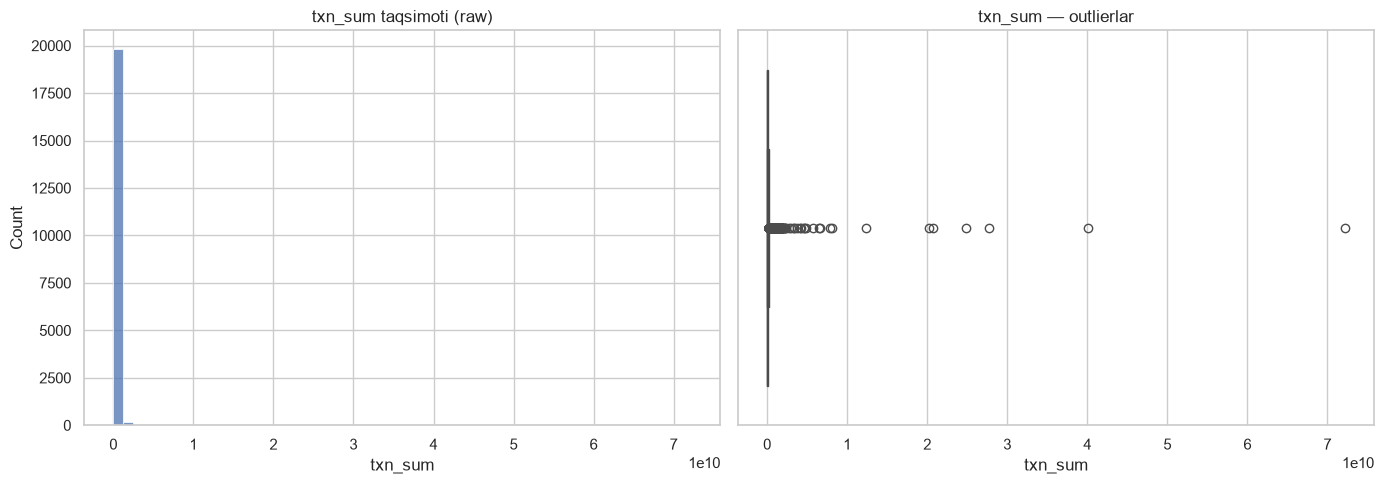

99-percentile: 1193376165.9799924
Max: 72202563600.0
99-perc dan yuqori mijozlar soni: 200


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.histplot(features["txn_sum"], bins=60, ax=axes[0])
axes[0].set_title("txn_sum taqsimoti (raw)")
sns.boxplot(x=features["txn_sum"], ax=axes[1])
axes[1].set_title("txn_sum — outlierlar")
plt.tight_layout(); plt.show()

print("99-percentile:", features["txn_sum"].quantile(0.99))
print("Max:", features["txn_sum"].max())
print("99-perc dan yuqori mijozlar soni:", (features["txn_sum"] > features["txn_sum"].quantile(0.99)).sum())


In [42]:
money_cols = ["txn_sum","txn_avg","txn_std","balance_mean","balance_std","balance_min","balance_max"]
features_log = features.copy()
for c in money_cols:
    features_log[c] = np.log1p(features_log[c].clip(lower=0))

features_log["balance_cv"] = features_log["balance_cv"].fillna(0).clip(0, 5)  # cheklab qo'yish
features_log.describe().T


,count,mean,std,min,25%,50%,75%,max
customer_id,"20,000.00","10,000.50","5,773.65",1.00,"5,000.75","10,000.50","15,000.25","20,000.00"
txn_cnt,"20,000.00",171.20,187.93,0.00,50.00,94.00,245.00,"4,164.00"
txn_sum,"20,000.00",16.99,2.86,0.00,16.47,17.43,18.22,25.00
txn_avg,"20,000.00",12.52,1.92,0.00,12.06,12.56,13.45,17.18
txn_std,"20,000.00",12.53,2.25,0.00,11.99,12.63,13.69,17.24
ch_share_atm,"20,000.00",0.26,0.16,0.00,0.13,0.26,0.38,1.00
ch_share_ecom,"20,000.00",0.23,0.20,0.00,0.07,0.17,0.34,1.00
ch_share_pos,"20,000.00",0.49,0.18,0.00,0.39,0.50,0.60,1.00
mcc_share_cash,"20,000.00",0.26,0.16,0.00,0.13,0.26,0.38,1.00
mcc_share_clothing,"20,000.00",0.05,0.05,0.00,0.00,0.03,0.08,0.38


## 4. EDA — Korrelyatsiya matritsasi

Multikollinearlik tekshiriladi. Kuchli korrelyatsiyali ustunlar (`balance_min`, `balance_max`, `mcc_share_cash`) klasterlash kirishidan olib tashlanadi, chunki ular boshqa ustunlarni takrorlaydi va bir xil signalga ortiqcha og'irlik beradi.

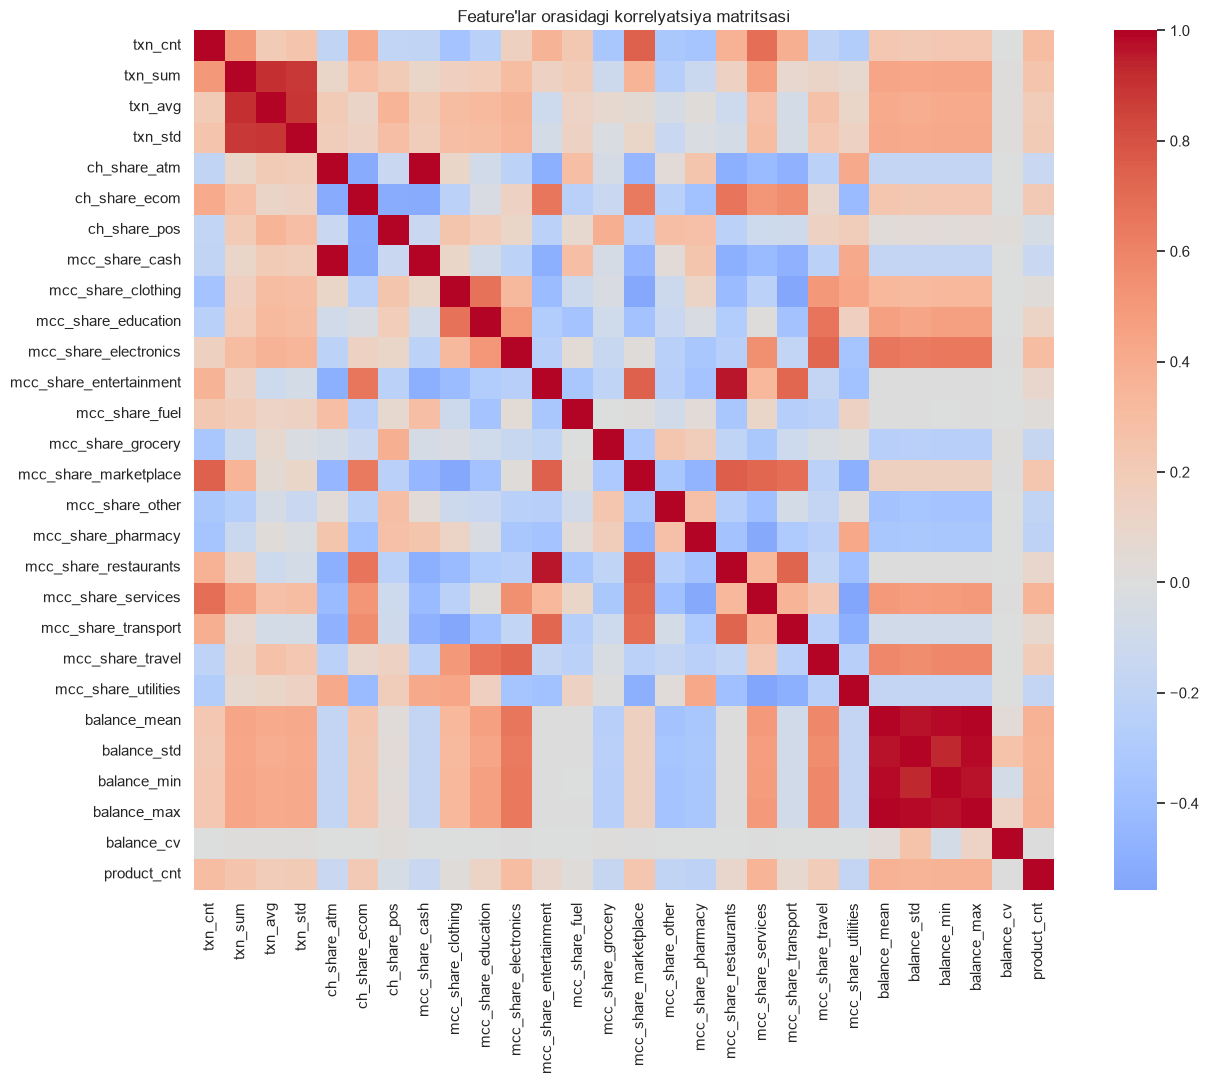

Yuqori korrelyatsiyali juftliklar (>0.85):
ch_share_atm             mcc_share_cash          1.00
balance_mean             balance_max             0.99
                         balance_min             0.99
balance_std              balance_max             0.99
balance_min              balance_max             0.97
balance_mean             balance_std             0.97
mcc_share_entertainment  mcc_share_restaurants   0.96
balance_std              balance_min             0.93
txn_sum                  txn_avg                 0.90
txn_avg                  txn_std                 0.89
txn_sum                  txn_std                 0.88
dtype: float64


In [43]:
feature_cols = [c for c in features_log.columns
                if c not in ("customer_id", "cluster", "turnover_quartile")]


corr = features_log[feature_cols].corr()

plt.figure(figsize=(14,11))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True)
plt.title("Feature'lar orasidagi korrelyatsiya matritsasi")
plt.tight_layout(); plt.show()

# |corr| > 0.85 bo'lgan juftliklar - multikollinearlik xavfi
high_corr = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
high_corr = high_corr[high_corr.abs() > 0.85].sort_values(key=abs, ascending=False)
print("Yuqori korrelyatsiyali juftliklar (>0.85):")
print(high_corr)


In [44]:
# --- Audit 3: tavtologiya tekshiruvi - net_revenue klasterlash kirishida bormi? ---
revenue_like = [c for c in feature_cols if "revenue" in c.lower()]
print("feature_cols ichida 'revenue' so'zi bor feature'lar:", revenue_like)
assert len(revenue_like) == 0, "TAVTOLOGIYA XAVFI: revenue klasterlash kirishida ishlatilmasligi kerak!"
print("✅ Tavtologiya yo'q — revenue faqat pul/nomlash bo'limida tashqi natija sifatida ishlatiladi.")


feature_cols ichida 'revenue' so'zi bor feature'lar: []
✅ Tavtologiya yo'q — revenue faqat pul/nomlash bo'limida tashqi natija sifatida ishlatiladi.


In [45]:
drop_cols_v2 = [ "balance_min", "balance_max", "mcc_share_cash"]
feature_cols_v2 = [c for c in feature_cols if c not in drop_cols_v2]
print("Qolgan feature_cols_v2:", len(feature_cols_v2), feature_cols_v2)

Qolgan feature_cols_v2: 25 ['txn_cnt', 'txn_sum', 'txn_avg', 'txn_std', 'ch_share_atm', 'ch_share_ecom', 'ch_share_pos', 'mcc_share_clothing', 'mcc_share_education', 'mcc_share_electronics', 'mcc_share_entertainment', 'mcc_share_fuel', 'mcc_share_grocery', 'mcc_share_marketplace', 'mcc_share_other', 'mcc_share_pharmacy', 'mcc_share_restaurants', 'mcc_share_services', 'mcc_share_transport', 'mcc_share_travel', 'mcc_share_utilities', 'balance_mean', 'balance_std', 'balance_cv', 'product_cnt']


In [46]:
feature_cols = feature_cols_v2

## 5. Klasterlash

6 oy davomida umuman operatsiya qilmagan mijozlar ("uxlab qolgan" segment, taxminan 359-370 kishi) klasterlashdan chiqarib tashlanadi va `active_features` sifatida alohida ushlanadi — ular xulq bo'yicha emas, faolsizligi bilan ajralib turadi, shuning uchun ularni faol mijozlar bilan bitta o'qda klasterlash noto'g'ri natija berardi. `txn_cnt` shu yerda log-transform qilinadi (`txn_sum` allaqachon oldingi bosqichda log qilingan, shuning uchun bu yerda qayta log qilinmaydi).

In [47]:
if 'balance_cv' in feature_cols: 
    feature_cols.remove('balance_cv')
active_features = features_log[(features_log['txn_cnt'] > 0) & (features_log['txn_sum'] > 0)].copy()
active_features['txn_cnt'] = np.log1p(active_features['txn_cnt'])


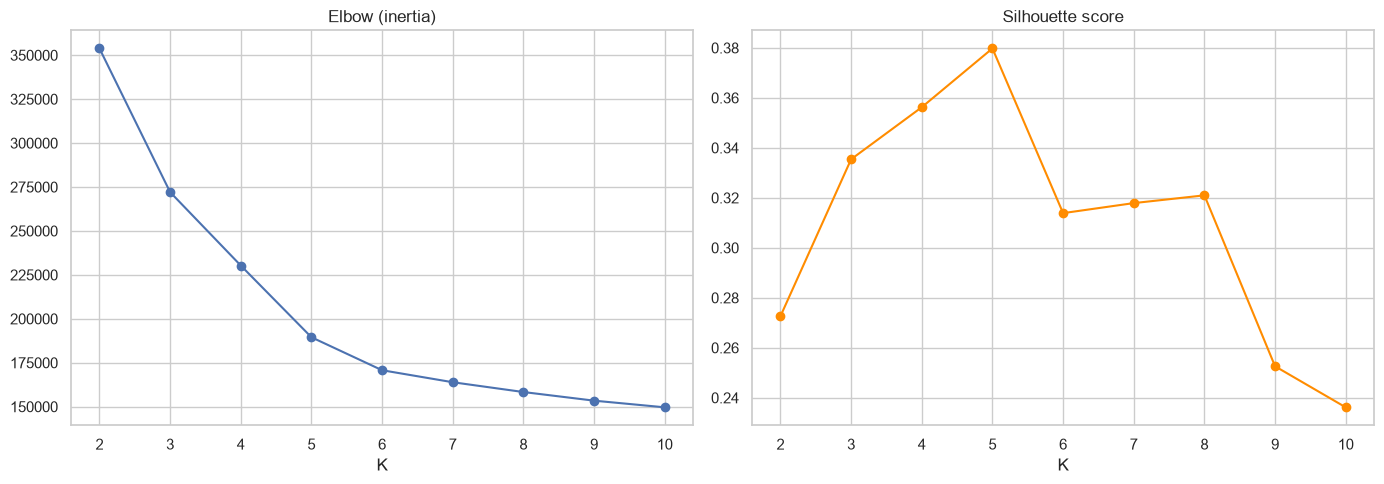

,K,inertia,silhouette
0,2,"353,857.87",0.27
1,3,"272,086.27",0.34
2,4,"230,312.70",0.36
3,5,"189,495.01",0.38
4,6,"170,732.87",0.31
5,7,"163,901.68",0.32
6,8,"158,323.84",0.32
7,9,"153,416.72",0.25
8,10,"149,625.24",0.24


In [48]:
X = StandardScaler().fit_transform(active_features[feature_cols])
inertias, sils = [], []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14,5))
axes[0].plot(list(K_range), inertias, marker="o")
axes[0].set_title("Elbow (inertia)"); axes[0].set_xlabel("K")
axes[1].plot(list(K_range), sils, marker="o", color="darkorange")
axes[1].set_title("Silhouette score"); axes[1].set_xlabel("K")
plt.tight_layout(); plt.show()

pd.DataFrame({"K": list(K_range), "inertia": inertias, "silhouette": sils})


In [49]:
K_FINAL = 5 # <-- silhouette/elbow va profil tahlilidan keyin shu yerni yakuniy songa o'zgartir

kmeans_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
#features_log["cluster"]
active_features["cluster"]= kmeans_final.fit_predict(X)

profile = active_features.groupby("cluster")[feature_cols].mean()
profile["n_customers"] = active_features["cluster"].value_counts().sort_index()
profile


,txn_cnt,txn_sum,txn_avg,txn_std,ch_share_atm,ch_share_ecom,ch_share_pos,mcc_share_clothing,mcc_share_education,mcc_share_electronics,...,mcc_share_pharmacy,mcc_share_restaurants,mcc_share_services,mcc_share_transport,mcc_share_travel,mcc_share_utilities,balance_mean,balance_std,product_cnt,n_customers
cluster,,,,,,,,,,,,,,,,,,,,,
0,3.99,17.89,13.91,13.95,0.17,0.27,0.56,0.12,0.12,0.16,...,0.01,0.00,0.08,0.00,0.16,0.01,16.69,15.53,2.12,2493
1,6.16,19.98,13.82,14.23,0.27,0.27,0.46,0.01,0.00,0.10,...,0.01,0.01,0.14,0.07,0.00,0.01,15.35,14.19,2.33,2306
2,5.61,17.71,12.11,12.21,0.12,0.47,0.42,0.00,0.00,0.00,...,0.00,0.21,0.08,0.18,0.00,0.00,14.39,13.22,1.69,4359
3,2.21,13.94,11.89,10.90,0.26,0.14,0.59,0.00,0.00,0.00,...,0.10,0.00,0.00,0.10,0.00,0.00,12.67,11.50,0.91,2225
4,4.42,17.08,12.67,12.79,0.37,0.11,0.52,0.07,0.03,0.00,...,0.08,0.00,0.00,0.00,0.00,0.13,13.97,12.80,1.17,8258


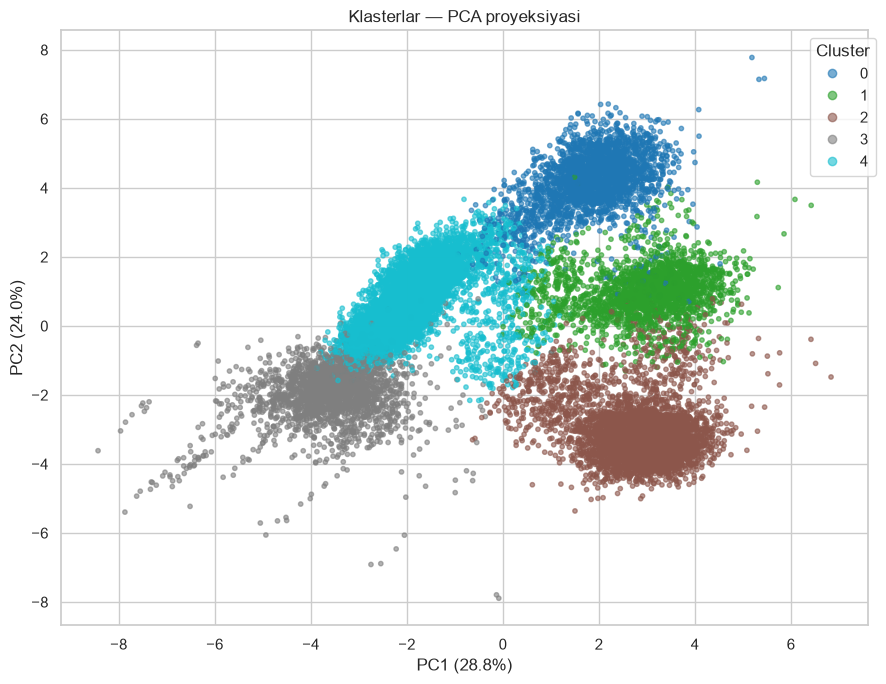

Tushuntirilgan variatsiya (PC1+PC2): 0.528


In [50]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(9,7))
scatter = plt.scatter(X_pca[:,0], X_pca[:,1], c=active_features["cluster"], cmap="tab10", s=10, alpha=0.6)
plt.legend(*scatter.legend_elements(), title="Cluster", bbox_to_anchor=(1.02,1))
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("Klasterlar — PCA proyeksiyasi")
plt.tight_layout(); plt.show()

print("Tushuntirilgan variatsiya (PC1+PC2):", pca.explained_variance_ratio_.sum().round(3))


## 6. Kvartil bo'yicha oddiy bo'linish bilan solishtirish

Klasterlash `active_features` ustida qilingani uchun solishtirish ham xuddi shu to'plamda (`active_features`) o'tkaziladi — aks holda klaster va kvartil turli mijoz to'plamlariga asoslangan bo'lib, taqqoslash noto'g'ri chiqadi.

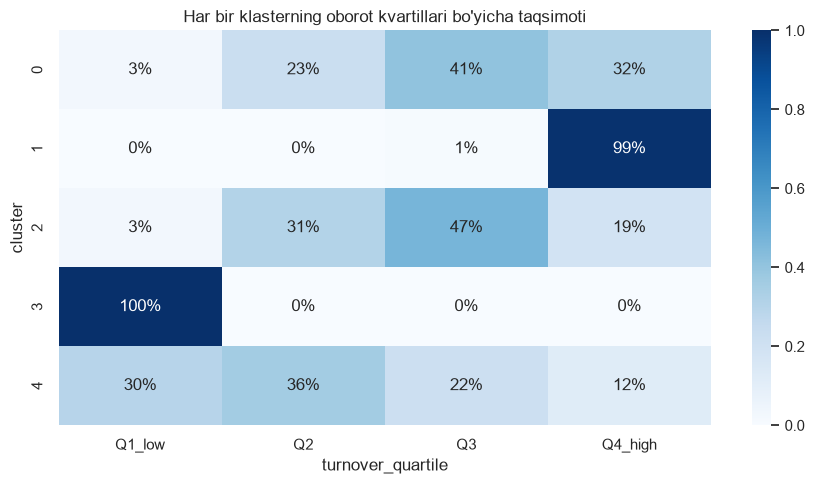

turnover_quartile,Q1_low,Q2,Q3,Q4_high
cluster,,,,
0,87,584,1033,789
1,0,0,23,2283
2,118,1370,2063,808
3,2223,2,0,0
4,2483,2954,1791,1030


In [51]:
active_features["turnover_quartile"] = pd.qcut(active_features["txn_sum"], 4, labels=["Q1_low","Q2","Q3","Q4_high"])

comparison = pd.crosstab(active_features["cluster"], active_features["turnover_quartile"])
comparison_pct = comparison.div(comparison.sum(axis=1), axis=0).round(2)

fig, ax = plt.subplots(figsize=(9,5))
sns.heatmap(comparison_pct, annot=True, fmt=".0%", cmap="Blues", ax=ax)
ax.set_title("Har bir klasterning oborot kvartillari bo'yicha taqsimoti")
plt.tight_layout(); plt.show()

comparison


In [52]:
rev_by_cust = rev_w.groupby("customer_id")["net_revenue_uzs"].sum().reset_index()
cmp_df = active_features[["customer_id","cluster","turnover_quartile","product_cnt"]].merge(rev_by_cust, on="customer_id", how="left")
cmp_df["net_revenue_uzs"] = cmp_df["net_revenue_uzs"].fillna(0)

def within_group_std(df, group_col, value_col):
    return df.groupby(group_col)[value_col].std().mean()

print("Klaster ichidagi o'rtacha std (net_revenue):", within_group_std(cmp_df, "cluster", "net_revenue_uzs"))
print("Kvartil ichidagi o'rtacha std (net_revenue):", within_group_std(cmp_df, "turnover_quartile", "net_revenue_uzs"))
print("Klaster ichidagi o'rtacha std (product_cnt):", within_group_std(cmp_df, "cluster", "product_cnt"))
print("Kvartil ichidagi o'rtacha std (product_cnt):", within_group_std(cmp_df, "turnover_quartile", "product_cnt"))


Klaster ichidagi o'rtacha std (net_revenue): 2521841.5984745715
Kvartil ichidagi o'rtacha std (net_revenue): 1765015.6096194515
Klaster ichidagi o'rtacha std (product_cnt): 1.1024010954587085
Kvartil ichidagi o'rtacha std (product_cnt): 1.1087074781113524


## 7. Barqarorlik (ARI)

Barcha stress-testlar (`other_random_state`, `half_sample`, `without_last_month`, `reduced_features`) bazaviy klaster yorlig'i bilan — `active_features["cluster"]` — solishtiriladi, izchillik saqlanadi.

In [53]:
results = {}

# (a) boshqa random_state
km_a = KMeans(n_clusters=K_FINAL, random_state=999, n_init=1).fit(X)
results["other_random_state"] = adjusted_rand_score(active_features["cluster"], km_a.labels_)

# (b) yarim tanlanma
df_half, _ = train_test_split(active_features, train_size=0.5, random_state=RANDOM_STATE)
scaler_half = StandardScaler()

X_half_scaled = scaler_half.fit_transform(df_half[feature_cols])

km_b = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=1).fit(X_half_scaled)
results["half_sample"] = adjusted_rand_score(df_half["cluster"], km_b.labels_)


# (c) oxirgi oysiz (2025-12 ni olib tashlab feature'larni qayta hisoblash)
txn_w_noDec = txn_w[txn_w["txn_ts"] < "2025-12-01"]
agg_c = txn_w_noDec.groupby("customer_id").agg(txn_cnt=("txn_id","count"), txn_sum=("amount_uzs","sum"),
                                                 txn_avg=("amount_uzs","mean"), txn_std=("amount_uzs","std")).reset_index()
feat_c = df_customers[["customer_id"]].merge(agg_c, on="customer_id", how="left").merge(fin, on="customer_id", how="left").merge(prod, on="customer_id", how="left")
feat_c = feat_c.fillna(0)
for c in ["txn_sum","txn_avg","txn_std","balance_mean","balance_std","balance_min","balance_max"]:
    feat_c[c] = np.log1p(feat_c[c].clip(lower=0))
common_cols_c = [c for c in ["txn_cnt","txn_sum","txn_avg","txn_std","balance_mean","balance_std",
                              "balance_min","balance_max","balance_cv","product_cnt"] if c in feat_c.columns]
# O'lik mijozlarni bu yerda ham filtrlaymiz
active_feat_c = feat_c[feat_c["customer_id"].isin(active_features["customer_id"])].set_index("customer_id").loc[active_features["customer_id"]].reset_index()

# balance_cv ni bu yerda ham olib tashlaymiz
cols_to_use_c = [col for col in common_cols_c if col != 'balance_cv']

Xc = StandardScaler().fit_transform(active_feat_c[cols_to_use_c].fillna(0))
km_c = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10).fit(Xc)
results["without_last_month"] = adjusted_rand_score(active_features["cluster"], km_c.labels_)
# (d) o'zgartirilgan feature to'plami - channel/mcc ulushlarisiz
reduced_cols = [c for c in feature_cols if not (c.startswith("ch_share_") or c.startswith("mcc_share_"))]
Xd = StandardScaler().fit_transform(active_features[reduced_cols])
km_d = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10).fit(Xd)
results["reduced_features"] = adjusted_rand_score(active_features["cluster"], km_d.labels_)


stability_table = pd.DataFrame(results.items(), columns=["stress_test", "ARI"]).round(3)
stability_table


,stress_test,ARI
0,other_random_state,1.00
1,half_sample,0.62
2,without_last_month,0.31
3,reduced_features,0.43


C:\Users\user\AppData\Local\Temp\ipykernel_16032\4217732258.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=stability_table, x="stress_test", y="ARI", palette="viridis")


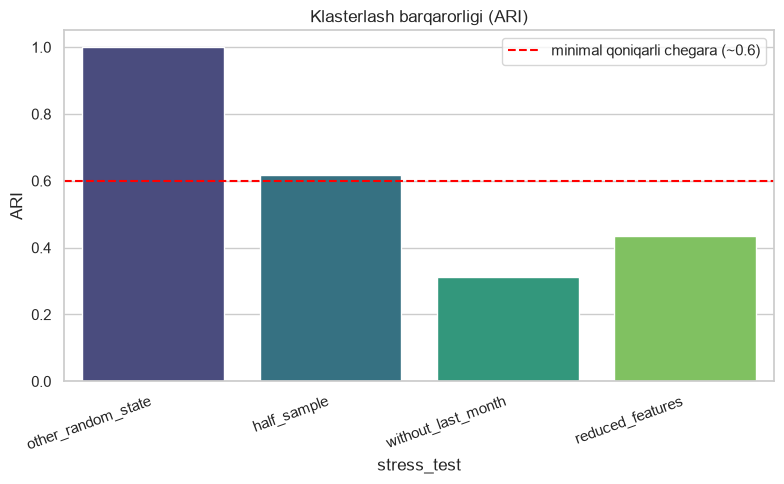

In [54]:
plt.figure(figsize=(8,5))
sns.barplot(data=stability_table, x="stress_test", y="ARI", palette="viridis")
plt.axhline(0.6, color="red", linestyle="--", label="minimal qoniqarli chegara (~0.6)")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.title("Klasterlash barqarorligi (ARI)")
plt.tight_layout(); plt.show()


## 8. Yangi mijozga qoida — nazoratlanuvchi classifier

RandomForest `active_features[feature_cols]` va `active_features["cluster"]` asosida o'qitiladi. Yangi mijoz uchun ham avval faollik tekshiriladi (agar 6 oyda operatsiyasi bo'lmasa — "uxlab qolgan" segmentga to'g'ridan-to'g'ri yuboriladi, classifierga yuborilmaydi), faol bo'lsa `clf.predict(...)` orqali klaster aniqlanadi.

Accuracy (yangi mijozni to'g'ri klasterga solish aniqligi): 0.982

              precision    recall  f1-score   support

           0       0.96      0.99      0.97       623
           1       0.95      0.98      0.97       577
           2       0.99      0.99      0.99      1090
           3       0.98      0.99      0.99       556
           4       1.00      0.97      0.98      2065

    accuracy                           0.98      4911
   macro avg       0.98      0.99      0.98      4911
weighted avg       0.98      0.98      0.98      4911



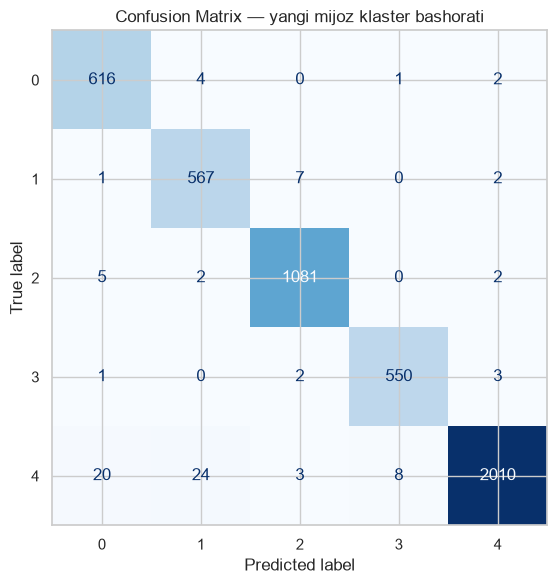

In [55]:
# ---- CELL A: model o'qitish + accuracy + confusion matrix + classification report ----
X_train, X_test, y_train, y_test = train_test_split(
    active_features[feature_cols], active_features["cluster"],
    test_size=0.25, random_state=RANDOM_STATE, stratify=active_features["cluster"]
)

clf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced")
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy (yangi mijozni to'g'ri klasterga solish aniqligi): {acc:.3f}")
print()
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(cm, display_labels=sorted(active_features["cluster"].unique())).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix — yangi mijoz klaster bashorati")
plt.tight_layout(); plt.show()


C:\Users\user\AppData\Local\Temp\ipykernel_16032\2114929607.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.head(15).values, y=importances.head(15).index, palette="mako")


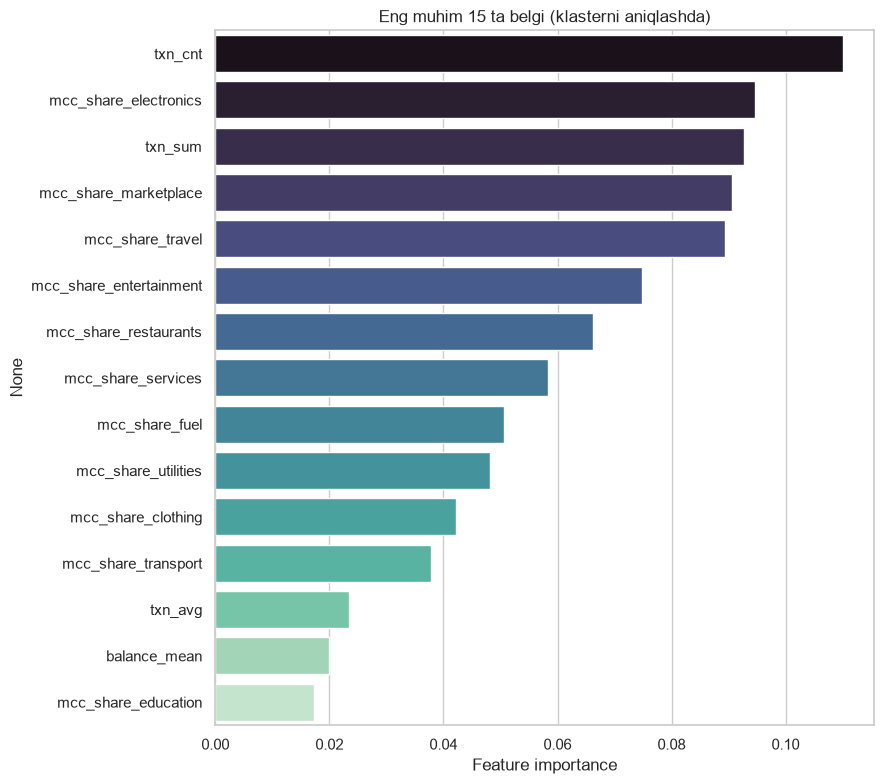

Muvaffaqiyat darajasi (yangi mijoz simulyatsiyasi): 98.2 %

Qoida: yangi mijoz uchun ham xuddi shu oynada (oxirgi mavjud 6 oy) feature'lar
hisoblanadi -> clf.predict(...) chaqiriladi -> u qaysi klasterga tushishi aniqlanadi.


In [56]:
# ---- CELL B: feature importance + amaliy qoida sifatida tekshiruv ----
importances = pd.Series(clf.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(9,8))
sns.barplot(x=importances.head(15).values, y=importances.head(15).index, palette="mako")
plt.title("Eng muhim 15 ta belgi (klasterni aniqlashda)")
plt.xlabel("Feature importance")
plt.tight_layout(); plt.show()

# Amaliy qoida sinovi: "yangi mijoz" simulyatsiyasi - test to'plamidagi mijozlarni
# xuddi ular yangi kelgandek, faqat feature'lari asosida klasterga solamiz
print("Muvaffaqiyat darajasi (yangi mijoz simulyatsiyasi):", round(acc*100, 1), "%")
print()
print("Qoida: yangi mijoz uchun ham xuddi shu oynada (oxirgi mavjud 6 oy) feature'lar")
print("hisoblanadi -> clf.predict(...) chaqiriladi -> u qaysi klasterga tushishi aniqlanadi.")


## 9. Klasterlarni nomlash, hajm va pul hisobi

Daromad va hajm hisobi `active_features` asosida qilinadi; "uxlab qolgan" segment (klasterlash tashqarisida qoldirilgan mijozlar) alohida qatorda, nol yoki deyarli nolga yaqin daromad bilan ko'rsatiladi.

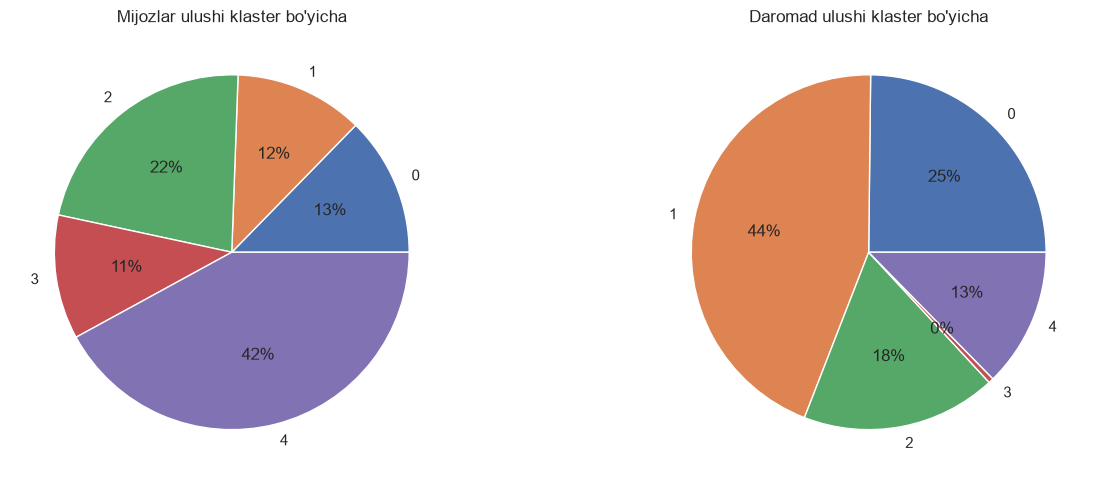

,n_customers,total_revenue_6m,avg_revenue_per_customer,share_of_customers_%,share_of_revenue_%
cluster,,,,,
0,2493,2980796573,"1,195,666.00",12.70,24.80
1,2306,5317419729,"2,305,906.00",11.70,44.30
2,4359,2135466104,"489,898.00",22.20,17.80
3,2225,56153620,"25,238.00",11.30,0.50
4,8258,1518427347,"183,873.00",42.00,12.60


In [57]:
money_summary = active_features[["customer_id","cluster"]].merge(rev_by_cust, on="customer_id", how="left")
money_summary["net_revenue_uzs"] = money_summary["net_revenue_uzs"].fillna(0)

cluster_money = money_summary.groupby("cluster").agg(
    n_customers=("customer_id","count"),
    total_revenue_6m=("net_revenue_uzs","sum"),
    avg_revenue_per_customer=("net_revenue_uzs","mean"),
).round(0)
cluster_money["share_of_customers_%"] = (cluster_money["n_customers"] / cluster_money["n_customers"].sum() * 100).round(1)
cluster_money["share_of_revenue_%"] = (cluster_money["total_revenue_6m"] / cluster_money["total_revenue_6m"].sum() * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14,5))
axes[0].pie(cluster_money["n_customers"], labels=cluster_money.index, autopct="%1.0f%%")
axes[0].set_title("Mijozlar ulushi klaster bo'yicha")
axes[1].pie(cluster_money["total_revenue_6m"], labels=cluster_money.index, autopct="%1.0f%%")
axes[1].set_title("Daromad ulushi klaster bo'yicha")
plt.tight_layout(); plt.show()

cluster_money



# Corrected Customer Segmentation Pipeline — leakage-aware and business-oriented

This section is the corrected pipeline. It is deliberately separate from the exploratory baseline above. It does not use `customer_id`, `full_name`, `crm_segment`, `turnover_total`, `net_revenue_uzs`, or any pre-existing segment as clustering inputs. Revenue is reserved for **post-cluster external validation**.

The redesign adds recency, tenure, activity regularity, temporal trend, channel/category diversity, product ecology, robust balance summaries, and an optional profile-only overlay. It also reports feature redundancy, cluster-size imbalance, local silhouette, pairwise separability, stability, and out-of-time business outcomes.

**Important:** this notebook does not invent or simulate results. If a table is unavailable, the relevant cell reports the limitation instead of fabricating metrics.


In [58]:
# Imports and safe local data access
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    silhouette_score, silhouette_samples, calinski_harabasz_score,
    davies_bouldin_score, adjusted_rand_score
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, cross_val_score

RANDOM_STATE = 42
WINDOW_START = pd.Timestamp('2025-07-01')
WINDOW_END = pd.Timestamp('2025-12-31')
TRAIN_END = pd.Timestamp('2025-09-30')
FUTURE_START = pd.Timestamp('2025-10-01')
FUTURE_END = pd.Timestamp('2025-12-31')
K_GRID = range(2, 11)
K_FINAL = 5

def get_existing(name, parquet_name):
    if name in globals() and isinstance(globals()[name], pd.DataFrame):
        return globals()[name].copy()
    candidates = [Path(parquet_name), Path('/content') / parquet_name, Path('/home/ubuntu') / parquet_name]
    for p in candidates:
        if p.exists():
            return pd.read_parquet(p)
    print(f'Missing {name}/{parquet_name}. Load the source table before running downstream cells.')
    return pd.DataFrame()

customers = get_existing('df_seg_customers', 'seg_customers.parquet')
transactions = get_existing('df_seg_transactions', 'seg_transactions.parquet')
balances = get_existing('df_seg_balances', 'seg_balances.parquet')
products = get_existing('df_seg_products', 'seg_products.parquet')
revenue = get_existing('df_seg_revenue_monthly', 'seg_revenue_monthly.parquet')

for df, date_cols in [(customers, ['birth_date','signup_date']), (transactions, ['txn_ts','month']), (balances, ['month_start']), (products, ['opened_at']), (revenue, ['month_start'])]:
    for c in date_cols:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors='coerce')


## 1. Leakage and data-quality audit

The audit is explicit. A column is forbidden from clustering if it is an identifier, an existing business label, a post-window outcome, or a summary that was computed using future data. The notebook checks this programmatically rather than relying on a verbal assertion.


In [59]:
# Leakage and data-quality audit
forbidden_exact = {
    'customer_id', 'full_name', 'crm_segment', 'turnover_total',
    'net_revenue_uzs', 'interchange_uzs', 'float_income_uzs',
    'transfer_fee_uzs', 'atm_cost_uzs'
}

def duplicate_key_report(df, key, name):
    if df.empty or key not in df.columns:
        return {'table': name, 'available': False}
    return {
        'table': name, 'available': True,
        'rows': len(df), 'null_keys': int(df[key].isna().sum()),
        'duplicate_keys': int(df[key].duplicated().sum())
    }

quality = pd.DataFrame([
    duplicate_key_report(customers, 'customer_id', 'customers'),
    duplicate_key_report(transactions, 'txn_id', 'transactions'),
    duplicate_key_report(balances, 'customer_id', 'balances'),
    duplicate_key_report(products, 'customer_id', 'products'),
    duplicate_key_report(revenue, 'customer_id', 'revenue')
])
display(quality)

if not customers.empty and 'customer_id' in customers.columns:
    print('Customer count:', customers['customer_id'].nunique())
if not transactions.empty and 'txn_ts' in transactions.columns:
    print('Transaction min/max:', transactions['txn_ts'].min(), transactions['txn_ts'].max())
if not revenue.empty and 'month_start' in revenue.columns:
    print('Revenue min/max:', revenue['month_start'].min(), revenue['month_start'].max())


,table,available,rows,null_keys,duplicate_keys
0,customers,True,20000,0,0
1,transactions,True,12136132,0,0
2,balances,True,427598,0,407598
3,products,True,29983,0,14139
4,revenue,True,427598,0,407598


Customer count: 20000
Transaction min/max: 2024-01-01 07:00:00 2025-12-28 23:59:00
Revenue min/max: 2024-01-01 00:00:00 2025-12-01 00:00:00


## 2. Leakage-safe, business-useful feature construction

The feature builder uses only observations available at a specified cutoff. This makes it possible to build a training snapshot ending on `TRAIN_END` and validate future outcomes in `FUTURE_START`–`FUTURE_END`. The same function is used for every cutoff, which avoids computing a feature with information from after the decision date.


In [60]:
def _safe_entropy(frame):
    p = frame.div(frame.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
    return -(p.where(p > 0, np.nan) * np.log(p.where(p > 0, np.nan))).sum(axis=1).fillna(0)

def build_customer_features(cutoff, start=WINDOW_START, end=None, include_profile=False):
    end = pd.Timestamp(end or cutoff)
    cutoff = pd.Timestamp(cutoff)
    if customers.empty or transactions.empty:
        return pd.DataFrame(), []

    c = customers.copy()
    tx = transactions.copy()
    tx = tx[(tx['txn_ts'] >= pd.Timestamp(start)) & (tx['txn_ts'] <= end)].copy()
    tx['amount_uzs'] = pd.to_numeric(tx['amount_uzs'], errors='coerce').fillna(0)
    tx['is_out'] = tx.get('direction', pd.Series(index=tx.index, dtype=object)).astype(str).str.lower().eq('out')
    out = tx[tx['is_out']].copy()
    ids = c[['customer_id']].drop_duplicates().copy()

    # Activity and monetary features are exposure-aware and robust to outliers.
    if out.empty:
        basic = pd.DataFrame(columns=['customer_id'])
    else:
        out['month_key'] = out['txn_ts'].dt.to_period('M').astype(str)
        basic = out.groupby('customer_id').agg(
            txn_cnt=('txn_id','count'),
            total_spend=('amount_uzs','sum'),
            median_txn=('amount_uzs','median'),
            p90_txn=('amount_uzs', lambda x: x.quantile(0.90)),
            txn_day_count=('txn_ts', lambda x: x.dt.normalize().nunique()),
            active_months=('month_key','nunique'),
            last_txn=('txn_ts','max'),
            first_txn=('txn_ts','min')
        ).reset_index()
        monthly = out.groupby(['customer_id','month_key']).agg(
            monthly_txn=('txn_id','count'), monthly_spend=('amount_uzs','sum')
        ).reset_index()
        monthly_cv = monthly.groupby('customer_id')['monthly_txn'].agg(
            lambda x: float(x.std(ddof=0) / x.mean()) if x.mean() else 0.0
        ).rename('monthly_txn_cv').reset_index()
        basic = basic.merge(monthly_cv, on='customer_id', how='left')

        channel_counts = out.groupby(['customer_id','channel'])['txn_id'].count().unstack(fill_value=0)
        channel_shares = channel_counts.div(channel_counts.sum(axis=1), axis=0).add_prefix('ch_share_')
        channel_shares['channel_entropy'] = _safe_entropy(channel_counts)
        channel_shares['n_active_channels'] = (channel_counts > 0).sum(axis=1)

        mcc_counts = out.groupby(['customer_id','mcc_group'])['txn_id'].count().unstack(fill_value=0)
        mcc_shares = mcc_counts.div(mcc_counts.sum(axis=1), axis=0)
        mcc_shares['mcc_entropy'] = _safe_entropy(mcc_counts)
        mcc_shares['mcc_top1_share'] = mcc_shares.drop(columns=['mcc_entropy'], errors='ignore').max(axis=1)
        for col in ['grocery','utilities','pharmacy','restaurants','entertainment','travel','electronics','fuel','transport']:
            if col in mcc_shares.columns:
                pass
        def share_sum(names):
            return mcc_shares[[x for x in names if x in mcc_shares.columns]].sum(axis=1)
        mcc_shares['essential_share'] = share_sum(['grocery','utilities','pharmacy'])
        mcc_shares['discretionary_share'] = share_sum(['restaurants','entertainment','travel','electronics','clothing'])
        mcc_shares = mcc_shares.add_prefix('mcc_')

        basic['log_total_spend'] = np.log1p(basic['total_spend'].clip(lower=0))
        basic['spend_per_active_month'] = basic['total_spend'] / basic['active_months'].clip(lower=1)
        basic['txn_per_active_month'] = basic['txn_cnt'] / basic['active_months'].clip(lower=1)
        basic['active_month_ratio'] = basic['active_months'] / max(1, len(pd.period_range(pd.Timestamp(start), end, freq='M')))
        basic['recency_days'] = (cutoff - basic['last_txn']).dt.days.clip(lower=0)
        basic['tenure_observed_days'] = (cutoff - basic['first_txn']).dt.days.clip(lower=0)
        basic['longest_gap_days'] = basic.apply(lambda r: max(0, (r['last_txn'] - r['first_txn']).days) if pd.notna(r['first_txn']) else 0, axis=1)

    features = ids.merge(basic, on='customer_id', how='left')

    # Customer profile and lifecycle features. Kept separately so they can be tested with explicit weights.
    if 'birth_date' in c.columns:
        features = features.merge(c[['customer_id','birth_date','gender','region','signup_date']].drop_duplicates('customer_id'), on='customer_id', how='left')
        features['age_years'] = ((cutoff - features['birth_date']).dt.days / 365.25).clip(lower=0, upper=110)
        features['tenure_months'] = ((cutoff - features['signup_date']).dt.days / 30.4375).clip(lower=0)

    if not balances.empty:
        b = balances.copy()
        b = b[(b['month_start'] >= pd.Timestamp(start)) & (b['month_start'] <= end)]
        b['avg_balance_uzs'] = pd.to_numeric(b['avg_balance_uzs'], errors='coerce').fillna(0)
        bal = b.groupby('customer_id')['avg_balance_uzs'].agg(
            balance_median='median', balance_p90=lambda x: x.quantile(.90),
            balance_mean='mean', balance_std=lambda x: x.std(ddof=0),
            balance_min='min', balance_max='max',
            positive_balance_months=lambda x: (x > 0).sum()
        ).reset_index()
        bal['balance_cv'] = bal['balance_std'] / bal['balance_mean'].replace(0, np.nan)
        features = features.merge(bal, on='customer_id', how='left')

    if not products.empty:
        p = products.copy()
        p = p[p['opened_at'] <= end] if 'opened_at' in p.columns else p
        prod = p.groupby('customer_id').agg(
            product_cnt=('product_code','nunique'), product_events=('product_code','count')
        ).reset_index()
        features = features.merge(prod, on='customer_id', how='left')
        if 'product_code' in p.columns:
            product_mix = pd.crosstab(p['customer_id'], p['product_code']).gt(0).astype(int)
            product_mix.columns = ['has_product_' + str(x) for x in product_mix.columns]
            product_mix = product_mix.reset_index()
            features = features.merge(product_mix, on='customer_id', how='left')

    numeric_cols = features.select_dtypes(include=[np.number]).columns.tolist()
    numeric_cols = [x for x in numeric_cols if x != 'customer_id']
    features[numeric_cols] = features[numeric_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
    features['is_inactive_window'] = (features.get('txn_cnt', 0) == 0).astype(int)

    # The profile columns are returned separately; no demographic column enters the baseline.
    profile_cols = [x for x in ['age_years','gender','region','tenure_months'] if x in features.columns]
    base_cols = [x for x in features.columns if x not in {'customer_id','birth_date','signup_date','gender','region','last_txn','first_txn','total_spend','balance_min','balance_max'}]
    base_cols = [x for x in base_cols if x not in {'is_inactive_window'}]
    if include_profile:
        base_cols += profile_cols
    return features, base_cols

features_train, candidate_feature_cols = build_customer_features(TRAIN_END, WINDOW_START, TRAIN_END, include_profile=False)
print('Training feature matrix:', features_train.shape)
print('Candidate clustering features:', candidate_feature_cols)


Training feature matrix: (20000, 42)
Candidate clustering features: ['txn_cnt', 'median_txn', 'p90_txn', 'txn_day_count', 'active_months', 'monthly_txn_cv', 'log_total_spend', 'spend_per_active_month', 'txn_per_active_month', 'active_month_ratio', 'recency_days', 'tenure_observed_days', 'longest_gap_days', 'age_years', 'tenure_months', 'balance_median', 'balance_p90', 'balance_mean', 'balance_std', 'positive_balance_months', 'balance_cv', 'product_cnt', 'product_events', 'has_product_cashback', 'has_product_credit_line', 'has_product_deposit', 'has_product_instalment', 'has_product_insurance', 'has_product_premium_sub', 'has_product_transfers_abroad', 'has_product_utilities_autopay']


## 3. Redundancy control and block weighting

The pipeline does not allow `txn_sum`, `txn_avg`, `txn_std`, balance scale and every MCC share to contribute as if they were independent dimensions. It detects highly correlated numeric columns and reports them before fitting. The baseline uses robust/log features; the original raw total remains available for descriptive profiling, not as an unexamined dominant axis.


In [61]:
# Correlation audit and controlled feature blocks
numeric_candidates = features_train[candidate_feature_cols].select_dtypes(include=np.number)
correlation = numeric_candidates.corr(method='spearman')
upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
redundant_pairs = (upper.stack().reset_index())
redundant_pairs.columns = ['feature_a','feature_b','spearman_abs']
redundant_pairs['spearman_abs'] = redundant_pairs['spearman_abs'].abs()
redundant_pairs = redundant_pairs[redundant_pairs['spearman_abs'] >= 0.80].sort_values('spearman_abs', ascending=False)
display(redundant_pairs.head(30))

feature_blocks = {
    'activity_recency': [c for c in ['recency_days','active_month_ratio','txn_day_count','longest_gap_days'] if c in candidate_feature_cols],
    'frequency': [c for c in ['txn_per_active_month','monthly_txn_cv'] if c in candidate_feature_cols],
    'monetary': [c for c in ['log_total_spend','median_txn','p90_txn','spend_per_active_month'] if c in candidate_feature_cols],
    'channel': [c for c in candidate_feature_cols if c.startswith('ch_share_')] + [c for c in ['channel_entropy','n_active_channels'] if c in candidate_feature_cols],
    'category': [c for c in ['mcc_entropy','mcc_mcc_top1_share','mcc_essential_share','mcc_discretionary_share'] if c in candidate_feature_cols],
    'financial': [c for c in ['balance_median','balance_p90','balance_cv','positive_balance_months'] if c in candidate_feature_cols],
    'engagement': [c for c in ['product_cnt','product_events'] if c in candidate_feature_cols],
    'lifecycle': [c for c in ['tenure_months'] if c in candidate_feature_cols],
}
feature_blocks = {k: list(dict.fromkeys(v)) for k,v in feature_blocks.items() if v}
print('Feature blocks:')
for block, cols in feature_blocks.items():
    print(f'{block}: {len(cols)} -> {cols}')

BLOCK_WEIGHTS = {
    'activity_recency': 1.00, 'frequency': 1.00, 'monetary': 0.75,
    'channel': 1.00, 'category': 0.75, 'financial': 0.75,
    'engagement': 1.00, 'lifecycle': 0.50
}

def make_weighted_matrix(df, blocks=feature_blocks, weights=BLOCK_WEIGHTS):
    cols = [c for block in blocks.values() for c in block if c in df.columns]
    cols = list(dict.fromkeys(cols))
    X = df[cols].copy()
    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=cols)
    for block, block_cols in blocks.items():
        block_cols = [c for c in block_cols if c in X_scaled.columns]
        if block_cols:
            X_scaled[block_cols] *= float(weights.get(block, 1.0))
    return X_scaled, cols, scaler

X_weighted, feature_cols, train_scaler = make_weighted_matrix(features_train)
print('Final numeric feature count:', len(feature_cols))


,feature_a,feature_b,spearman_abs
133,active_months,active_month_ratio,1.00
673,product_cnt,product_events,1.00
513,balance_p90,balance_mean,1.00
482,balance_median,balance_mean,1.00
193,log_total_spend,spend_per_active_month,0.99
8,txn_cnt,txn_per_active_month,0.99
3,txn_cnt,txn_day_count,0.99
481,balance_median,balance_p90,0.99
101,txn_day_count,txn_per_active_month,0.98
33,median_txn,p90_txn,0.95


Feature blocks:
activity_recency: 4 -> ['recency_days', 'active_month_ratio', 'txn_day_count', 'longest_gap_days']
frequency: 2 -> ['txn_per_active_month', 'monthly_txn_cv']
monetary: 4 -> ['log_total_spend', 'median_txn', 'p90_txn', 'spend_per_active_month']
financial: 4 -> ['balance_median', 'balance_p90', 'balance_cv', 'positive_balance_months']
engagement: 2 -> ['product_cnt', 'product_events']
lifecycle: 1 -> ['tenure_months']
Final numeric feature count: 17


## 4. Model comparison: feature sets and K values

The notebook compares K values rather than presenting one K as inherently true. The default `K_FINAL=5` preserves comparability with the baseline, but the score table exposes whether the new feature design improves cohesion, separation, balance, and stability.


In [62]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np

# Indexlarni qayta moslaymiz
features_train = features_train.reset_index(drop=True).copy()
X_weighted = X_weighted.reset_index(drop=True).astype(np.float32)

# Cluster label bo‘lmasa, avtomatik yaratamiz
if 'cluster' not in features_train.columns:
    final_model = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=30,
        algorithm='lloyd'
    )
    features_train['cluster'] = final_model.fit_predict(X_weighted)

if len(features_train) != len(X_weighted):
    raise ValueError(
        f'Row mismatch: features_train={len(features_train)}, '
        f'X_weighted={len(X_weighted)}'
    )


def pairwise_cluster_diagnostics_windows_safe(
    df,
    X,
    label_col='cluster',
    n_estimators=200
):
    y_all = df[label_col].astype(int).reset_index(drop=True)
    X_all = X.reset_index(drop=True)

    results = []
    importances = {}
    cluster_values = sorted(y_all.unique())

    for i, cluster_a in enumerate(cluster_values):
        for cluster_b in cluster_values[i + 1:]:
            print(f'Processing Cluster {cluster_a} vs Cluster {cluster_b} ...')

            mask = y_all.isin([cluster_a, cluster_b])
            X_pair = X_all.loc[mask].reset_index(drop=True)
            y_pair = y_all.loc[mask].reset_index(drop=True)

            class_counts = y_pair.value_counts()
            min_class_count = int(class_counts.min())

            if min_class_count < 5:
                print('Skipped: one class has fewer than 5 observations.')
                continue

            n_splits = min(5, min_class_count)
            cv = StratifiedKFold(
                n_splits=n_splits,
                shuffle=True,
                random_state=42
            )

            # Windows-safe: no multiprocessing
            clf = RandomForestClassifier(
                n_estimators=n_estimators,
                random_state=42,
                class_weight='balanced',
                n_jobs=1
            )

            # Windows-safe cross-validation
            scores = cross_val_score(
                clf,
                X_pair,
                y_pair,
                cv=cv,
                scoring='accuracy',
                n_jobs=1
            )

            clf.fit(X_pair, y_pair)

            # Windows-safe permutation importance
            try:
                perm = permutation_importance(
                    clf,
                    X_pair,
                    y_pair,
                    n_repeats=2,
                    random_state=42,
                    scoring='accuracy',
                    n_jobs=1
                )

                importance = pd.Series(
                    perm.importances_mean,
                    index=X_pair.columns
                ).sort_values(ascending=False)

            except Exception as error:
                print('Permutation importance failed; using RF impurity importance:', error)
                importance = pd.Series(
                    clf.feature_importances_,
                    index=X_pair.columns
                ).sort_values(ascending=False)

            results.append({
                'cluster_a': cluster_a,
                'cluster_b': cluster_b,
                'cv_accuracy_mean': float(scores.mean()),
                'cv_accuracy_std': float(scores.std()),
                'n_pair': int(len(y_pair)),
                'n_a': int((y_pair == cluster_a).sum()),
                'n_b': int((y_pair == cluster_b).sum())
            })

            importances[(cluster_a, cluster_b)] = importance.head(10)

    return pd.DataFrame(results), importances


pairwise_results, pairwise_importance = pairwise_cluster_diagnostics_windows_safe(
    features_train,
    X_weighted,
    label_col='cluster',
    n_estimators=200
)

print('\nPairwise CV results:')
display(pairwise_results)

for pair, importance in pairwise_importance.items():
    print(f'\nTop features separating Cluster {pair[0]} vs Cluster {pair[1]}:')
    display(importance.to_frame('importance'))


Processing Cluster 0 vs Cluster 1 ...
Processing Cluster 0 vs Cluster 2 ...
Processing Cluster 0 vs Cluster 3 ...
Processing Cluster 0 vs Cluster 4 ...
Processing Cluster 1 vs Cluster 2 ...
Processing Cluster 1 vs Cluster 3 ...
Processing Cluster 1 vs Cluster 4 ...
Processing Cluster 2 vs Cluster 3 ...
Processing Cluster 2 vs Cluster 4 ...
Processing Cluster 3 vs Cluster 4 ...

Pairwise CV results:


,cluster_a,cluster_b,cv_accuracy_mean,cv_accuracy_std,n_pair,n_a,n_b
0,0,1,1.00,0.00,5421,9,5412
1,0,2,1.00,0.00,2516,9,2507
2,0,3,1.00,0.00,1390,9,1381
3,0,4,1.00,0.00,10700,9,10691
4,1,2,0.99,0.00,7919,5412,2507
5,1,3,1.00,0.00,6793,5412,1381
6,1,4,0.99,0.00,16103,5412,10691
7,2,3,1.00,0.00,3888,2507,1381
8,2,4,0.99,0.00,13198,2507,10691
9,3,4,1.00,0.00,12072,1381,10691



Top features separating Cluster 0 vs Cluster 1:


,importance
recency_days,0.00
active_month_ratio,0.00
txn_day_count,0.00
longest_gap_days,0.00
txn_per_active_month,0.00
monthly_txn_cv,0.00
log_total_spend,0.00
median_txn,0.00
p90_txn,0.00
spend_per_active_month,0.00



Top features separating Cluster 0 vs Cluster 2:


...

,importance
longest_gap_days,0.03
active_month_ratio,0.01
product_events,0.00
product_cnt,0.00
balance_p90,0.00
monthly_txn_cv,0.00
balance_cv,0.00
median_txn,0.00
recency_days,0.00
p90_txn,0.00



Top features separating Cluster 2 vs Cluster 4:


,importance
product_cnt,0.06
product_events,0.05
balance_p90,0.03
balance_median,0.02
median_txn,0.01
p90_txn,0.01
balance_cv,0.00
txn_per_active_month,0.00
monthly_txn_cv,0.00
txn_day_count,0.00



Top features separating Cluster 3 vs Cluster 4:


,importance
longest_gap_days,0.06
active_month_ratio,0.05
recency_days,0.01
monthly_txn_cv,0.00
balance_p90,0.00
balance_median,0.00
tenure_months,0.00
txn_day_count,0.00
balance_cv,0.00
p90_txn,0.00


## 5. Pairwise separability and feature evidence

The global Random Forest reconstruction score is not used as business success. It is replaced by pairwise diagnostics that show which features separate each cluster pair. This is descriptive evidence about the clustering geometry, not future behavior prediction.


In [63]:
def pairwise_cluster_diagnostics(df, X, label_col='cluster', n_estimators=500):
    results = []
    importances = {}
    labels = df[label_col].astype(int)
    for a in sorted(labels.unique()):
        for b in sorted(labels.unique()):
            if a >= b:
                continue
            mask = labels.isin([a,b])
            X_pair = X.loc[mask]
            y_pair = labels.loc[mask]
            clf = RandomForestClassifier(n_estimators=n_estimators, random_state=RANDOM_STATE, class_weight='balanced')
            scores = cross_val_score(clf, X_pair, y_pair, cv=5, scoring='accuracy')
            clf.fit(X_pair, y_pair)
            perm = permutation_importance(clf, X_pair, y_pair, n_repeats=5, random_state=RANDOM_STATE, scoring='accuracy')
            imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
            importances[(a,b)] = imp.head(10)
            results.append({'cluster_a':a, 'cluster_b':b, 'cv_accuracy_mean':scores.mean(), 'cv_accuracy_std':scores.std(), 'n_pair':int(mask.sum())})
    return pd.DataFrame(results), importances

pairwise_results, pairwise_importance = pairwise_cluster_diagnostics(features_train, X_weighted)
display(pairwise_results)
for pair, imp in pairwise_importance.items():
    print('Top features for pair', pair)
    display(imp.to_frame('permutation_importance'))

# Centroid differences and standardized effect size for every pair.
centroids = features_train.groupby('cluster')[feature_cols].mean()
for a, b in [(2,4), (0,1), (3,4)]:
    if a in centroids.index and b in centroids.index:
        diff = (centroids.loc[a] - centroids.loc[b]).abs().sort_values(ascending=False)
        print(f'Largest absolute centroid differences: {a} vs {b}')
        display(diff.head(15).to_frame('absolute_centroid_difference'))


,cluster_a,cluster_b,cv_accuracy_mean,cv_accuracy_std,n_pair
0,0,1,1.00,0.00,5421
1,0,2,1.00,0.00,2516
2,0,3,1.00,0.00,1390
3,0,4,1.00,0.00,10700
4,1,2,0.99,0.00,7919
5,1,3,1.00,0.00,6793
6,1,4,0.99,0.00,16103
7,2,3,1.00,0.00,3888
8,2,4,0.99,0.00,13198
9,3,4,0.99,0.00,12072


Top features for pair (np.int64(0), np.int64(1))


,permutation_importance
recency_days,0.00
active_month_ratio,0.00
txn_day_count,0.00
longest_gap_days,0.00
txn_per_active_month,0.00
monthly_txn_cv,0.00
log_total_spend,0.00
median_txn,0.00
p90_txn,0.00
spend_per_active_month,0.00


Top features for pair (np.int64(0), np.int64(2))


,permutation_importance
recency_days,0.00
active_month_ratio,0.00
txn_day_count,0.00
longest_gap_days,0.00
txn_per_active_month,0.00
monthly_txn_cv,0.00
log_total_spend,0.00
balance_p90,0.00
balance_median,0.00
product_events,0.00


...

,absolute_centroid_difference
balance_p90,"24,475,498.20"
balance_median,"19,069,760.37"
spend_per_active_month,"7,600,080.19"
p90_txn,"1,340,201.25"
median_txn,"511,839.29"
txn_day_count,4.47
txn_per_active_month,2.77
tenure_months,2.64
product_events,1.68
product_cnt,1.68


Largest absolute centroid differences: 0 vs 1


,absolute_centroid_difference
spend_per_active_month,"2,174,106,174.87"
balance_p90,"274,117,324.72"
balance_median,"192,558,243.08"
p90_txn,"29,060,043.83"
median_txn,"10,542,341.54"
txn_per_active_month,110.34
tenure_months,5.03
log_total_spend,4.37
longest_gap_days,3.75
txn_day_count,1.02


Largest absolute centroid differences: 3 vs 4


,absolute_centroid_difference
balance_p90,"923,696.78"
spend_per_active_month,"755,376.78"
balance_median,"503,882.77"
p90_txn,"292,590.99"
median_txn,"75,426.53"
longest_gap_days,68.37
txn_day_count,24.43
recency_days,10.01
tenure_months,8.37
log_total_spend,7.47


## 6. Out-of-time external validation

The only meaningful business validation uses a future period that was not used to form the clusters. The model clusters the customer snapshot at `TRAIN_END`; future revenue, activity and product adoption are evaluated in `FUTURE_START`–`FUTURE_END`. This is separate from any label-reconstruction classifier.


In [64]:
def future_outcomes(start=FUTURE_START, end=FUTURE_END):
    if transactions.empty and revenue.empty:
        return pd.DataFrame(columns=['customer_id'])
    out = pd.DataFrame({'customer_id': customers['customer_id'].drop_duplicates()}) if not customers.empty else pd.DataFrame(columns=['customer_id'])
    if not transactions.empty:
        tx = transactions.copy()
        tx['txn_ts'] = pd.to_datetime(tx['txn_ts'], errors='coerce')
        tx = tx[(tx['txn_ts'] >= start) & (tx['txn_ts'] <= end)]
        tx['amount_uzs'] = pd.to_numeric(tx['amount_uzs'], errors='coerce').fillna(0)
        future_tx = tx.groupby('customer_id').agg(
            future_txn_count=('txn_id','count'), future_active_days=('txn_ts', lambda x: x.dt.normalize().nunique()),
            future_spend=('amount_uzs','sum')
        ).reset_index()
        out = out.merge(future_tx, on='customer_id', how='left')
    if not revenue.empty and 'net_revenue_uzs' in revenue.columns:
        rv = revenue.copy()
        rv['month_start'] = pd.to_datetime(rv['month_start'], errors='coerce')
        rv = rv[(rv['month_start'] >= start) & (rv['month_start'] <= end)]
        fut_rev = rv.groupby('customer_id')['net_revenue_uzs'].sum().rename('future_net_revenue').reset_index()
        out = out.merge(fut_rev, on='customer_id', how='left')
    for col in out.columns:
        if col != 'customer_id':
            out[col] = out[col].fillna(0)
    out['future_active'] = (out.get('future_txn_count', 0) > 0).astype(int)
    return out

future = future_outcomes()
external = features_train[['customer_id','cluster']].merge(future, on='customer_id', how='left')
external_summary = external.groupby('cluster').agg(
    n_customers=('customer_id','count'),
    future_active_rate=('future_active','mean'),
    future_txn_count=('future_txn_count','mean'),
    future_spend=('future_spend','mean'),
    future_net_revenue=('future_net_revenue','mean')
).sort_index()
display(external_summary)

# Kruskal-Wallis is used as a distributional screening test; it is not treated as causal proof.
try:
    from scipy.stats import kruskal
    for metric in ['future_active','future_spend','future_net_revenue']:
        groups = [g[metric].dropna().values for _, g in external.groupby('cluster') if len(g[metric].dropna()) > 1]
        if len(groups) >= 2:
            print(metric, kruskal(*groups))
except Exception as exc:
    print('External statistical test unavailable:', exc)


,n_customers,future_active_rate,future_txn_count,future_spend,future_net_revenue
cluster,,,,,
0,9,1.00,537.33,"9,909,461,038.56","46,257,527.00"
1,5412,1.00,200.71,"140,919,775.17","558,189.49"
2,2507,1.00,40.38,"55,994,707.97","565,975.31"
3,1381,0.70,20.57,"12,765,518.32","73,708.07"
4,10691,1.00,49.58,"20,276,059.39","105,995.57"


future_active KruskalResult(statistic=np.float64(5580.582885285128), pvalue=np.float64(0.0))
future_spend KruskalResult(statistic=np.float64(7741.6966832312455), pvalue=np.float64(0.0))
future_net_revenue KruskalResult(statistic=np.float64(9720.536956489947), pvalue=np.float64(0.0))


## 7. Stability and sensitivity audit

The corrected notebook reports stability under repeated initializations, half-sample perturbation, reduced feature blocks, and time-window changes. The expected interpretation is not “one ARI is enough”, but a distribution of ARI values with explicit sensitivity to time and feature design.


In [65]:
def fit_labels(X, k=K_FINAL, seed=RANDOM_STATE):
    return KMeans(n_clusters=k, random_state=seed, n_init=50).fit_predict(X)

base_labels = features_train['cluster'].to_numpy()
stability_rows = []
for seed in [0, 1, 7, 19, 42, 99]:
    labels = fit_labels(X_weighted, K_FINAL, seed)
    stability_rows.append({'test':'random_seed', 'seed':seed, 'ari_vs_base': adjusted_rand_score(base_labels, labels)})

rng = np.random.default_rng(RANDOM_STATE)
for i in range(10):
    idx = rng.choice(len(X_weighted), size=max(2, len(X_weighted)//2), replace=False)
    labels_half = fit_labels(X_weighted.iloc[idx], K_FINAL, RANDOM_STATE)
    stability_rows.append({'test':'half_sample', 'seed':i, 'ari_vs_base_on_sample': adjusted_rand_score(base_labels[idx], labels_half)})

# Feature ablation: remove one block at a time and compare labels on the same customers.
for block in feature_blocks:
    ablated = {k:v for k,v in feature_blocks.items() if k != block}
    X_ab, _, _ = make_weighted_matrix(features_train, blocks=ablated, weights=BLOCK_WEIGHTS)
    labels_ab = fit_labels(X_ab, K_FINAL, RANDOM_STATE)
    stability_rows.append({'test':'remove_block', 'seed':block, 'ari_vs_base': adjusted_rand_score(base_labels, labels_ab)})

stability_report = pd.DataFrame(stability_rows)
display(stability_report)


,test,seed,ari_vs_base,ari_vs_base_on_sample
0,random_seed,0,0.74,NaN
1,random_seed,1,0.74,NaN
2,random_seed,7,1.00,NaN
3,random_seed,19,0.74,NaN
4,random_seed,42,0.74,NaN
5,random_seed,99,0.74,NaN
6,half_sample,0,NaN,0.74
7,half_sample,1,NaN,0.74
8,half_sample,2,NaN,0.98
9,half_sample,3,NaN,0.73


## 8. Demographic and geographic overlay — controlled, not blindly added

Age, gender, region and tenure are retained for profiling first. A second experiment can include age/tenure as low-weight numeric variables and gender/region with one-hot encoding or a mixed-type method. The notebook does not claim that demographic variables improve segmentation until the comparison table demonstrates improvement in stability and future outcomes without unfairly dominating behavior.


In [69]:
# 3.5 K ni baholash uchun helper - buni make_weighted_matrix dan keyin qo'ying
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

def evaluate_k_grid(X, k_grid=K_GRID, random_state=RANDOM_STATE, n_init=30):
    rows = []
    for k in k_grid:
        km = KMeans(n_clusters=k, random_state=random_state, n_init=n_init, algorithm='lloyd')
        labels = km.fit_predict(X)
        # silhouette kamida 2 ta klaster va har birida 2+ nuqta bo'lganda hisoblanadi
        try:
            sil = silhouette_score(X, labels)
        except:
            sil = np.nan
        try:
            ch = calinski_harabasz_score(X, labels)
            db = davies_bouldin_score(X, labels)
        except:
            ch, db = np.nan, np.nan
            
        # balans - eng katta klaster ulushi
        vc = pd.Series(labels).value_counts(normalize=True)
        rows.append({
            'k': k,
            'silhouette': sil,
            'calinski_harabasz': ch,
            'davies_bouldin': db,
            'inertia': km.inertia_,
            'max_cluster_share': vc.max(),
            'min_cluster_share': vc.min()
        })
    return pd.DataFrame(rows).set_index('k').round(3)

In [70]:
# Profile-only cross-tabulation: no demographic variable changes the cluster geometry.
profile_cols = [c for c in ['age_years','gender','region','tenure_months'] if c in features_train.columns]
for col in profile_cols:
    if col in ['gender','region']:
        table = pd.crosstab(features_train['cluster'], features_train[col], normalize='index')
        print(f'Profile distribution: {col}')
        display(table)
    else:
        display(features_train.groupby('cluster')[col].agg(['count','mean','median','std']))

# Optional numeric lifecycle overlay; this is an experiment, not the default.
profile_numeric = [c for c in ['age_years','tenure_months'] if c in features_train.columns]
if profile_numeric:
    blocks_with_profile = dict(feature_blocks)
    blocks_with_profile['profile_numeric'] = profile_numeric
    profile_weights = dict(BLOCK_WEIGHTS)
    profile_weights['profile_numeric'] = 0.25
    X_profile, profile_cols_used, _ = make_weighted_matrix(features_train, blocks=blocks_with_profile, weights=profile_weights)
    profile_metrics = evaluate_k_grid(X_profile)
    print('Behavior + low-weight numeric profile experiment')
    display(profile_metrics)


,count,mean,median,std
cluster,,,,
0,9,41.72,40.80,10.58
1,5412,38.60,38.62,10.98
2,2507,38.57,38.84,11.09
3,1381,38.64,38.43,11.00
4,10691,38.58,38.50,11.03


Profile distribution: gender


gender,F,M
cluster,,
0,0.22,0.78
1,0.34,0.66
2,0.33,0.67
3,0.35,0.65
4,0.34,0.66


Profile distribution: region


region,Andijan,Bukhara,Fergana,Jizzakh,Karakalpakstan,Kashkadarya,Khorezm,Namangan,Navoi,Samarkand,Sirdarya,Surkhandarya,Tashkent
cluster,,,,,,,,,,,,,
0,0.44,0.00,0.00,0.00,0.11,0.11,0.00,0.00,0.11,0.00,0.11,0.00,0.11
1,0.07,0.08,0.08,0.07,0.08,0.08,0.08,0.08,0.08,0.07,0.07,0.07,0.08
2,0.07,0.08,0.08,0.07,0.08,0.07,0.08,0.08,0.08,0.07,0.08,0.08,0.07
3,0.08,0.08,0.07,0.08,0.08,0.08,0.08,0.08,0.07,0.09,0.07,0.06,0.08
4,0.08,0.08,0.08,0.08,0.08,0.08,0.08,0.08,0.08,0.08,0.08,0.08,0.08


,count,mean,median,std
cluster,,,,
0,9,36.81,43.83,24.43
1,5412,41.84,41.51,22.85
2,2507,42.51,42.38,22.38
3,1381,31.50,29.27,26.16
4,10691,39.87,39.66,23.20


Behavior + low-weight numeric profile experiment


,silhouette,calinski_harabasz,davies_bouldin,inertia,max_cluster_share,min_cluster_share
k,,,,,,
2,0.51,"4,983.22",1.17,"201,381.14",0.92,0.08
3,0.24,"4,798.77",1.52,"169,980.58",0.59,0.07
4,0.25,"4,286.81",1.36,"153,097.71",0.54,0.07
5,0.24,"4,015.32",1.30,"139,504.06",0.53,0.00
6,0.26,"3,870.72",1.29,"127,828.50",0.53,0.00
7,0.25,"3,793.00",1.21,"117,646.16",0.45,0.00
8,0.24,"3,789.88",1.19,"108,106.59",0.44,0.00
9,0.21,"3,746.27",1.21,"100,657.96",0.39,0.00
10,0.21,"3,638.91",1.26,"95,349.19",0.35,0.00


## 9. Interpretation policy and limitations

The corrected notebook uses the following interpretation rules:

- A cluster mean describes a group; it does not prove causation.
- A high cluster-assignment accuracy only reconstructs an unsupervised label; it is not future-revenue accuracy.
- A large cluster is not automatically bad; it must be tested for internal heterogeneity.
- Demographic variables are useful for profiling and controlled hybrid experiments, but should not silently dominate behavior.
- A segment is production-ready only after out-of-time outcome validation, repeated stability testing, operational assignment testing, and governance review.
- If the future period is unavailable, the notebook reports that external validation cannot be completed rather than inventing a positive result.
